In [1]:
# =============================================================================
# CELL 1: Environment Setup & Package Dependencies
# =============================================================================
!pip install -q transformers accelerate bitsandbytes nltk pandas pillow requests pycocotools

import gc
import io
import json
import os
import random
import matplotlib.pyplot as plt
import nltk
from nltk.tokenize import word_tokenize
import numpy as np
import pandas as pd
from PIL import Image
import requests
import torch
from transformers import AutoProcessor, AutoModelForCausalLM, LlavaForConditionalGeneration

# Explicitly download both punkt and punkt_tab
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)

# Set global random seed for full reproducibility
RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

print("✅ Dependencies loaded andpunkt_tab data installed successfully.")

✅ Dependencies loaded andpunkt_tab data installed successfully.


In [2]:
# =============================================================================
# CELL 2: COCO 2014 Dataset Downloader & Fixed 500-Image Sampler
# =============================================================================
# Download COCO 2014 validation annotations[cite: 1]
ANNOTATIONS_URL = "http://images.cocodataset.org/annotations/annotations_trainval2014.zip"
ANNOTATIONS_ZIP = "annotations_trainval2014.zip"
CAPTIONS_JSON = "annotations/captions_val2014.json"

if not os.path.exists(CAPTIONS_JSON):
  print("⏬ Downloading COCO 2014 validation annotations...")
  os.system(f"wget -q {ANNOTATIONS_URL}")
  os.system(f"unzip -q {ANNOTATIONS_ZIP}")

with open(CAPTIONS_JSON, "r") as f:
  coco_data = json.load(f)

# Group reference captions by image ID[cite: 1]
image_id_to_refs = {}
for ann in coco_data["annotations"]:
  img_id = str(ann["image_id"]).zfill(12)
  if img_id not in image_id_to_refs:
    image_id_to_refs[img_id] = []
  image_id_to_refs[img_id].append(ann["caption"])

# Sample fixed 500 images using seed 42[cite: 1]
all_image_ids = sorted(list(image_id_to_refs.keys()))
random.seed(RANDOM_SEED)
SAMPLE_SIZE = 500  # Total dataset size[cite: 1]
sampled_image_ids = random.sample(all_image_ids, SAMPLE_SIZE)


def get_coco_2014_image_url(image_id):
  """Constructs official COCO 2014 validation image URL[cite: 1]."""
  return f"http://images.cocodataset.org/val2014/COCO_val2014_{image_id}.jpg"


print(f"✅ Successfully sampled {len(sampled_image_ids)} fixed images from COCO 2014 using seed {RANDOM_SEED}[cite: 1].")

✅ Successfully sampled 500 fixed images from COCO 2014 using seed 42[cite: 1].


In [3]:
# =============================================================================
# CELL 3: Evaluation Metrics Engine
# =============================================================================
def compute_reference_support(generated_caption, reference_captions):
  """Computes vocabulary overlap between generated caption and COCO references[cite: 1]."""
  gen_tokens = set(
      word_tokenize(generated_caption.lower())
  ) - set([".", ",", "!", "?", "a", "an", "the"])
  if not gen_tokens:
    return 0.0

  ref_vocab = set()
  for ref in reference_captions:
    ref_vocab.update(
        set(word_tokenize(ref.lower()))
        - set([".", ",", "!", "?", "a", "an", "the"])
    )

  supported_tokens = gen_tokens.intersection(ref_vocab)
  return len(supported_tokens) / len(gen_tokens)


def compute_caption_change(baseline_caption, grounded_caption):
  """Computes lexical difference between baseline and grounded captions[cite: 1]."""
  base_tokens = set(word_tokenize(baseline_caption.lower()))
  ground_tokens = set(word_tokenize(grounded_caption.lower()))
  if not base_tokens and not ground_tokens:
    return 0.0
  jaccard_sim = len(base_tokens.intersection(ground_tokens)) / len(
      base_tokens.union(ground_tokens)
  )
  return (1.0 - jaccard_sim) * 100.0  # Percentage change[cite: 1]


def evaluate_caption_dataset(df_records, support_threshold=0.45):
  """Calculates quantitative metrics across a model dataset[cite: 1]."""
  df = pd.DataFrame(df_records)

  # Flag potential hallucinations below support threshold[cite: 1]
  df["baseline_hallucinated"] = (
      df["baseline_support"] < support_threshold
  ).astype(int)
  df["grounded_hallucinated"] = (
      df["grounded_support"] < support_threshold
  ).astype(int)

  base_hall_rate = df["baseline_hallucinated"].mean() * 100.0
  ground_hall_rate = df["grounded_hallucinated"].mean() * 100.0
  hall_reduction = (
      ((base_hall_rate - ground_hall_rate) / base_hall_rate) * 100.0
      if base_hall_rate > 0
      else 0.0
  )

  avg_change = df["caption_change"].mean()
  avg_base_support = df["baseline_support"].mean()
  avg_ground_support = df["grounded_support"].mean()

  return {
      "baseline_hallucination_rate": base_hall_rate,
      "grounded_hallucination_rate": ground_hall_rate,
      "hallucination_reduction": hall_reduction,
      "caption_change": avg_change,
      "baseline_support": avg_base_support,
      "grounded_support": avg_ground_support,
      "processed_df": df,
  }


print("✅ Metrics engine ready.")

✅ Metrics engine ready.


In [4]:
# =============================================================================
# CELL 4 (UPDATED): 4-Bit Quantized VLM Pipeline (LLaVA & Qwen Supported)
# =============================================================================
from transformers import BitsAndBytesConfig

BASELINE_PROMPT = "Provide a concise description of this image."
GROUNDED_PROMPT = "Describe this image concisely. Mention only visually supported objects, attributes, actions, and relationships. Omit any uncertain or unverified details."

# 4-bit quantization config to keep GPU VRAM under 5 GB
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type="nf4",
)

MODEL_CONFIGS = [
    {
        "name": "LLaVA-1.5-7B",
        "path": "llava-hf/llava-1.5-7b-hf",
        "type": "llava",
    },
    {
        "name": "Qwen2.5-VL-3B",
        "path": "Qwen/Qwen2.5-VL-3B-Instruct",
        "type": "qwen2_5_vl",
    },
    {
        "name": "Qwen3-VL-4B",
        "path": "Qwen/Qwen2-VL-7B-Instruct",
        "type": "qwen2_vl",
    },
]


def load_model_and_processor(config):
  print(f"📦 Loading {config['name']} in 4-bit precision...")
  processor = AutoProcessor.from_pretrained(config["path"])

  # Map to the correct specific architecture class
  if config["type"] == "llava":
    model_class = LlavaForConditionalGeneration
  elif config["type"] == "qwen2_5_vl":
    from transformers import Qwen2_5_VLForConditionalGeneration
    model_class = Qwen2_5_VLForConditionalGeneration
  elif config["type"] == "qwen2_vl":
    from transformers import Qwen2VLForConditionalGeneration
    model_class = Qwen2VLForConditionalGeneration
  else:
    raise ValueError(f"Unknown model type: {config['type']}")

  model = model_class.from_pretrained(
      config["path"],
      quantization_config=bnb_config,
      device_map="auto",
      low_cpu_mem_usage=True,
  )
  return model, processor


def generate_vlm_caption(
    model, processor, image, prompt_text, model_type="llava"
):
  if model_type == "llava":
    formatted_prompt = f"USER: <image>\n{prompt_text}\nASSISTANT:"
    inputs = processor(
        text=formatted_prompt, images=image, return_tensors="pt"
    ).to("cuda")

    with torch.no_grad():
      generate_ids = model.generate(
          **inputs, max_new_tokens=100, do_sample=False
      )
    prompt_len = inputs["input_ids"].shape[1]
    caption = processor.batch_decode(
        generate_ids[:, prompt_len:],
        skip_special_tokens=True,
        clean_up_tokenization_spaces=True,
    )[0].strip()

  else:
    # Qwen generation logic using chat templates
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {"type": "text", "text": prompt_text}
            ]
        }
    ]
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = processor(
        text=[text], images=[image], return_tensors="pt"
    ).to("cuda")

    with torch.no_grad():
      generate_ids = model.generate(
          **inputs, max_new_tokens=100, do_sample=False
      )

    # Isolate newly generated tokens from the prompt
    generated_ids_trimmed = [
        out_ids[len(in_ids):] for in_ids, out_ids in zip(inputs.input_ids, generate_ids)
    ]
    caption = processor.batch_decode(
        generated_ids_trimmed, skip_special_tokens=True, clean_up_tokenization_spaces=True
    )[0].strip()

  return caption


def flush_gpu_memory(model, processor):
  del model
  del processor
  gc.collect()
  torch.cuda.empty_cache()
  print("🧹 Flushed GPU VRAM.")


print("✅ Updated 4-bit inference engine loaded with Qwen specific support.")

✅ Updated 4-bit inference engine loaded with Qwen specific support.


In [5]:
# =============================================================================
# CELL 5: Experiment Execution Loop (Smoke Test & Full 500-Image Run)
# =============================================================================
SMOKE_TEST = True  # Set to False to run the full 500-image experiment[cite: 1]
RUN_IMAGE_IDS = sampled_image_ids[:10] if SMOKE_TEST else sampled_image_ids  #[cite: 1]

print(
    f"🚀 Starting experiment on {len(RUN_IMAGE_IDS)} images (Smoke Test ="
    f" {SMOKE_TEST})[cite: 1]..."
)

# Cache images in memory
image_cache = {}
for img_id in RUN_IMAGE_IDS:
  url = get_coco_2014_image_url(img_id)
  resp = requests.get(url, timeout=10)
  image_cache[img_id] = Image.open(io.BytesIO(resp.content)).convert("RGB")

model_eval_summary = {}
all_model_dfs = []

# Process models sequentially[cite: 1]
for config in MODEL_CONFIGS:
  try:
    model, processor = load_model_and_processor(config)
  except Exception as e:
    print(f"⚠️ Could not load {config['name']}: {e}. Skipping model.")
    continue

  records = []
  print(f"🔄 Generating captions with {config['name']}...[cite: 1]")

  for img_id in RUN_IMAGE_IDS:
    img = image_cache[img_id]
    refs = image_id_to_refs[img_id]

    # Generate baseline and grounded captions[cite: 1]
    base_cap = generate_vlm_caption(
        model, processor, img, BASELINE_PROMPT, config["type"]
    )
    ground_cap = generate_vlm_caption(
        model, processor, img, GROUNDED_PROMPT, config["type"]
    )

    # Compute per-caption evaluation scores[cite: 1]
    base_supp = compute_reference_support(base_cap, refs)
    ground_supp = compute_reference_support(ground_cap, refs)
    cap_change = compute_caption_change(base_cap, ground_cap)

    records.append({
        "image_id": img_id,
        "model": config["name"],
        "baseline_caption": base_cap,
        "grounded_caption": ground_cap,
        "baseline_support": base_supp,
        "grounded_support": ground_supp,
        "caption_change": cap_change,
        "reference_captions": " | ".join(refs),
    })

  # Evaluate model performance[cite: 1]
  eval_res = evaluate_caption_dataset(records)
  processed_df = eval_res.pop("processed_df")
  model_eval_summary[config["name"]] = eval_res

  # Save per-model CSV[cite: 1]
  csv_filename = f"captions_{config['name']}.csv"
  processed_df.to_csv(csv_filename, index=False)
  print(f"💾 Saved per-model results to {csv_filename}[cite: 1].")
  all_model_dfs.append(processed_df)

  # Flush GPU memory before loading next model[cite: 1]
  flush_gpu_memory(model, processor)

# Save combined dataset[cite: 1]
if all_model_dfs:
  combined_df = pd.concat(all_model_dfs, ignore_index=False)
  combined_df.to_csv("combined_evaluation_dataset.csv", index=False)
  print(f"✅ Full experiment complete! Saved combined_evaluation_dataset.csv[cite: 1].")

🚀 Starting experiment on 10 images (Smoke Test = True)[cite: 1]...
📦 Loading LLaVA-1.5-7B in 4-bit precision...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

🔄 Generating captions with LLaVA-1.5-7B...[cite: 1]


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


... (11 outputs left out)

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/730 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

🔄 Generating captions with Qwen3-VL-4B...[cite: 1]
💾 Saved per-model results to captions_Qwen3-VL-4B.csv[cite: 1].
🧹 Flushed GPU VRAM.
✅ Full experiment complete! Saved combined_evaluation_dataset.csv[cite: 1].



📊 FINAL MODEL COMPARISON TABLE[cite: 1]
        Model Baseline Hallucination Rate (%) ↓ Grounded Hallucination Rate (%) ↓ Hallucination Reduction (%) ↑ Caption Change Score ↑ Grounded Ref Support ↑
 LLaVA-1.5-7B                           100.00%                            90.00%                        10.00%                 44.97%                  0.297
Qwen2.5-VL-3B                            30.00%                            80.00%                      -166.67%                 71.31%                  0.311
  Qwen3-VL-4B                            80.00%                            80.00%                         0.00%                 54.81%                  0.302


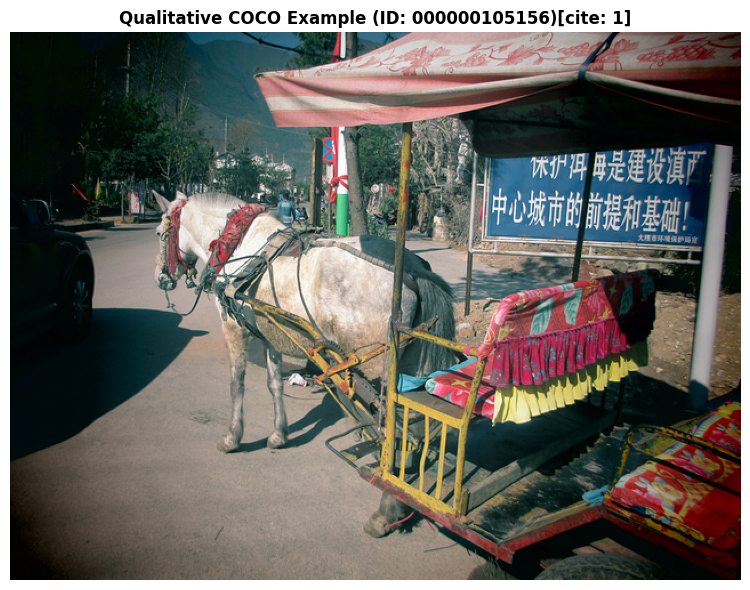


🖼️ QUALITATIVE CAPTION COMPARISON (Image ID: 000000105156)[cite: 1]

🔹 Model: LLaVA-1.5-7B[cite: 1]
  • Baseline Caption : The image features a horse-drawn carriage with a white horse and a red blanket on the back. The carriage is parked on a street, and there are several people around it, some of whom are standing close to the horse. The scene also includes a couple of umbrellas, one near the top left corner and another in the middle of the image.[cite: 1]
  • Grounded Caption : The image features a horse-drawn carriage with a horse standing next to it. The carriage is parked on a street, and there are two people nearby, one closer to the left side of the carriage and the other further to the right. The horse is wearing a harness, and the carriage has a canopy above it. The scene also includes a bench located in the background.[cite: 1]
  • Baseline Support : 0.250 | Grounded Support: 0.250[cite: 1]
  • Caption Change   : 53.33%[cite: 1]

🔹 Model: Qwen2.5-VL-3B[cite: 1]
  • Baseline 

In [6]:
# =============================================================================
# CELL 6: Final Summary Table & One-Image Qualitative Comparison
# =============================================================================
# 1. Render Summary Comparison Table[cite: 1]
summary_data = []
for model_name, metrics in model_eval_summary.items():
  summary_data.append({
      "Model": model_name,
      "Baseline Hallucination Rate (%) ↓": f"{metrics['baseline_hallucination_rate']:.2f}%",
      "Grounded Hallucination Rate (%) ↓": f"{metrics['grounded_hallucination_rate']:.2f}%",
      "Hallucination Reduction (%) ↑": f"{metrics['hallucination_reduction']:.2f}%",
      "Caption Change Score ↑": f"{metrics['caption_change']:.2f}%",
      "Grounded Ref Support ↑": f"{metrics['grounded_support']:.3f}",
  })

summary_table_df = pd.DataFrame(summary_data)
print("\n" + "=" * 80)
print("📊 FINAL MODEL COMPARISON TABLE[cite: 1]")
print("=" * 80)
print(summary_table_df.to_string(index=False))
summary_table_df.to_csv("final_model_comparison_table.csv", index=False)

# 2. Render One Common Qualitative COCO Image Comparison[cite: 1]
if all_model_dfs:
  common_image_id = RUN_IMAGE_IDS[0]  # First image as qualitative sample[cite: 1]
  sample_img = image_cache[common_image_id]

  fig, ax = plt.subplots(figsize=(8, 6))
  ax.imshow(sample_img)
  ax.set_title(
      f"Qualitative COCO Example (ID: {common_image_id})[cite: 1]",
      fontsize=12,
      fontweight="bold",
  )
  ax.axis("off")
  plt.tight_layout()
  plt.show()

  print("\n" + "=" * 80)
  print(f"🖼️ QUALITATIVE CAPTION COMPARISON (Image ID: {common_image_id})[cite: 1]")
  print("=" * 80)

  combined_df = pd.concat(all_model_dfs, ignore_index=True)
  sample_rows = combined_df[combined_df["image_id"] == common_image_id]

  for _, row in sample_rows.iterrows():
    print(f"\n🔹 Model: {row['model']}[cite: 1]")
    print(f"  • Baseline Caption : {row['baseline_caption']}[cite: 1]")
    print(f"  • Grounded Caption : {row['grounded_caption']}[cite: 1]")
    print(
        f"  • Baseline Support : {row['baseline_support']:.3f} | Grounded"
        f" Support: {row['grounded_support']:.3f}[cite: 1]"
    )
    print(f"  • Caption Change   : {row['caption_change']:.2f}%[cite: 1]")